In [ ]:
# Resolve the repository root so data/ and output/ paths work from any working directory
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "data").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Start

The scatter plot of Ntl per capita and expenditure per capita

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
import statsmodels.api as sm
import linearmodels.panel as plm
import statsmodels.formula.api as smf


plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10
sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'

# Reading the Data

In [58]:
# ============================================================
# Read Data
# ============================================================

df_master = pd.read_excel(
    str(ROOT / "data/Validation/hies_ntl_gdp_master.xlsx")
)

print(df_master.shape)
print(df_master.columns.tolist())
print(df_master.isnull().sum())

(434, 19)
['Province_EN', 'Year', 'avg_exp_per_capita', 'real_exp_per_capita', 'Annual_Sum', 'Annual_Mean', 'NTL_Per_Capita', 'Population', 'GDP', 'GDP_per_Capita', 'log_Annual_Sum', 'log_Annual_Mean', 'log_NTL_Per_Capita', 'log_avg_exp_per_capita', 'log_real_exp_per_capita', 'log_GDP', 'log_GDP_per_Capita', 'GDP_score', 'NTL_score']
Province_EN                 0
Year                        0
avg_exp_per_capita          0
real_exp_per_capita         0
Annual_Sum                 31
Annual_Mean                31
NTL_Per_Capita             31
Population                 31
GDP                        93
GDP_per_Capita             93
log_Annual_Sum             31
log_Annual_Mean            31
log_NTL_Per_Capita         31
log_avg_exp_per_capita      0
log_real_exp_per_capita     0
log_GDP                    93
log_GDP_per_Capita         93
GDP_score                  93
NTL_score                  31
dtype: int64


# Annual NTL vs Expenditure 

in this part I validate NTL with Expenditure but not any NTL it is Sum NTL which differnce with mean NTL is Annual NTL is the mean of NTL of each pixel of a province and sum is simply the total light for a province no matter the number of the pixels

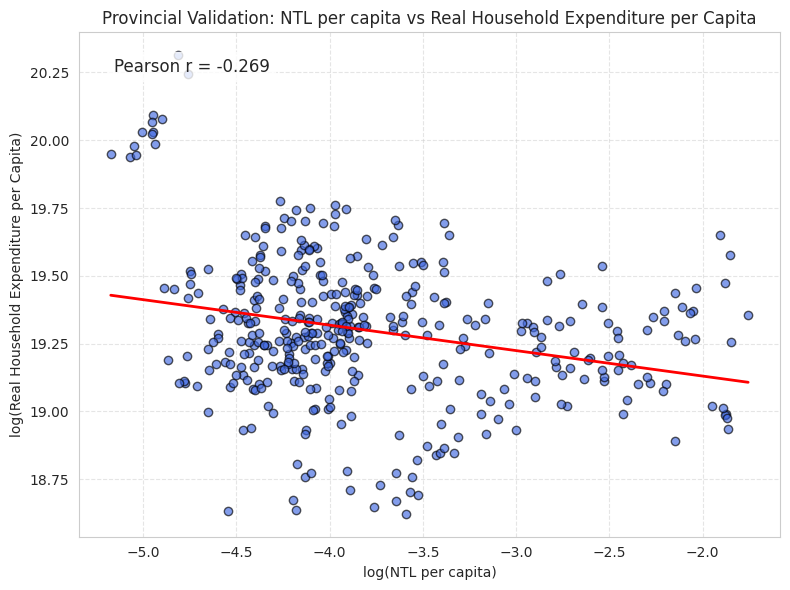

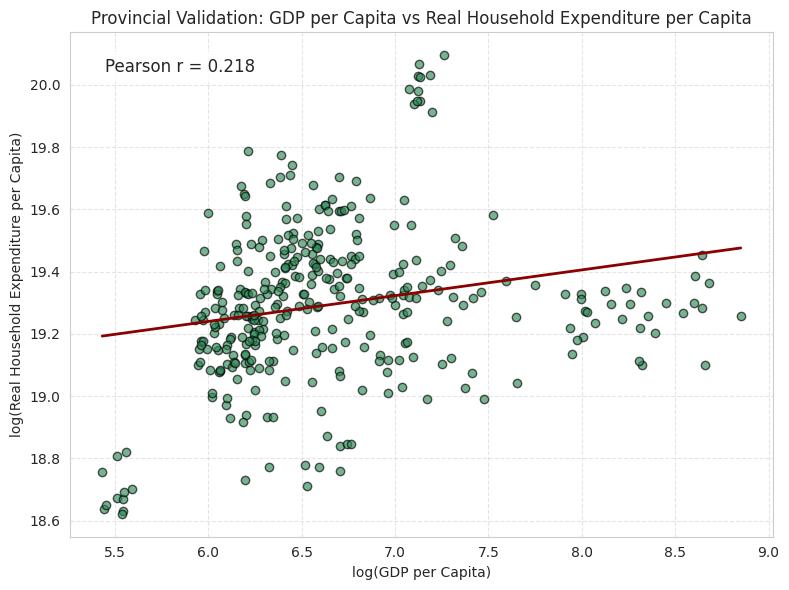

In [59]:
# ============================================================
# Scatter 1: NTL Annual Mean vs Real Household Expenditure per Capita
# ============================================================

df_plot1 = df_master[['log_NTL_Per_Capita', 'log_real_exp_per_capita']].dropna()

r1, _ = pearsonr(df_plot1['log_NTL_Per_Capita'], df_plot1['log_real_exp_per_capita'])
beta1, intercept1 = np.polyfit(df_plot1['log_NTL_Per_Capita'], df_plot1['log_real_exp_per_capita'], 1)

plt.figure(figsize=(8, 6))
plt.scatter(df_plot1['log_NTL_Per_Capita'], df_plot1['log_real_exp_per_capita'],
            alpha=0.65, edgecolors='k', color='royalblue')

x1 = np.linspace(df_plot1['log_NTL_Per_Capita'].min(), df_plot1['log_NTL_Per_Capita'].max(), 100)
plt.plot(x1, intercept1 + beta1 * x1, color='red', linewidth=2)

plt.text(0.05, 0.95, f'Pearson r = {r1:.3f}',
         transform=plt.gca().transAxes, fontsize=12,
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8))

plt.title('Provincial Validation: NTL per capita vs Real Household Expenditure per Capita')
plt.xlabel('log(NTL per capita)')
plt.ylabel('log(Real Household Expenditure per Capita)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# ============================================================
# Scatter 2: GDP per Capita vs Real Household Expenditure per Capita
# ============================================================

df_plot2 = df_master[['log_GDP_per_Capita', 'log_real_exp_per_capita']].dropna()

r2, _ = pearsonr(df_plot2['log_GDP_per_Capita'], df_plot2['log_real_exp_per_capita'])
beta2, intercept2 = np.polyfit(df_plot2['log_GDP_per_Capita'], df_plot2['log_real_exp_per_capita'], 1)

plt.figure(figsize=(8, 6))
plt.scatter(df_plot2['log_GDP_per_Capita'], df_plot2['log_real_exp_per_capita'],
            alpha=0.65, edgecolors='k', color='seagreen')

x2 = np.linspace(df_plot2['log_GDP_per_Capita'].min(), df_plot2['log_GDP_per_Capita'].max(), 100)
plt.plot(x2, intercept2 + beta2 * x2, color='darkred', linewidth=2)

plt.text(0.05, 0.95, f'Pearson r = {r2:.3f}',
         transform=plt.gca().transAxes, fontsize=12,
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8))

plt.title('Provincial Validation: GDP per Capita vs Real Household Expenditure per Capita')
plt.xlabel('log(GDP per Capita)')
plt.ylabel('log(Real Household Expenditure per Capita)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

for robustness purposes we check if the non log version behave the same

In [60]:
# Check if the relationship makes sense without log
df_check = df_master[['NTL_Per_Capita', 'real_exp_per_capita']].dropna()
r_raw, _ = pearsonr(df_check['NTL_Per_Capita'], df_check['real_exp_per_capita'])
print(f"Raw correlation (no log): {r_raw:.3f}")

# Check by year to remove panel effects
for year, group in df_master.dropna(subset=['NTL_Per_Capita', 'real_exp_per_capita']).groupby('Year'):
    r, _ = pearsonr(group['NTL_Per_Capita'], group['real_exp_per_capita'])
    print(f"Year {year}: r = {r:.3f}")

Raw correlation (no log): -0.186
Year 1391: r = -0.376
Year 1392: r = -0.135
Year 1393: r = -0.149
Year 1394: r = -0.191
Year 1395: r = -0.088
Year 1396: r = -0.153
Year 1397: r = -0.178
Year 1398: r = -0.295
Year 1399: r = -0.194
Year 1400: r = -0.284
Year 1401: r = -0.281
Year 1402: r = -0.249
Year 1403: r = -0.221


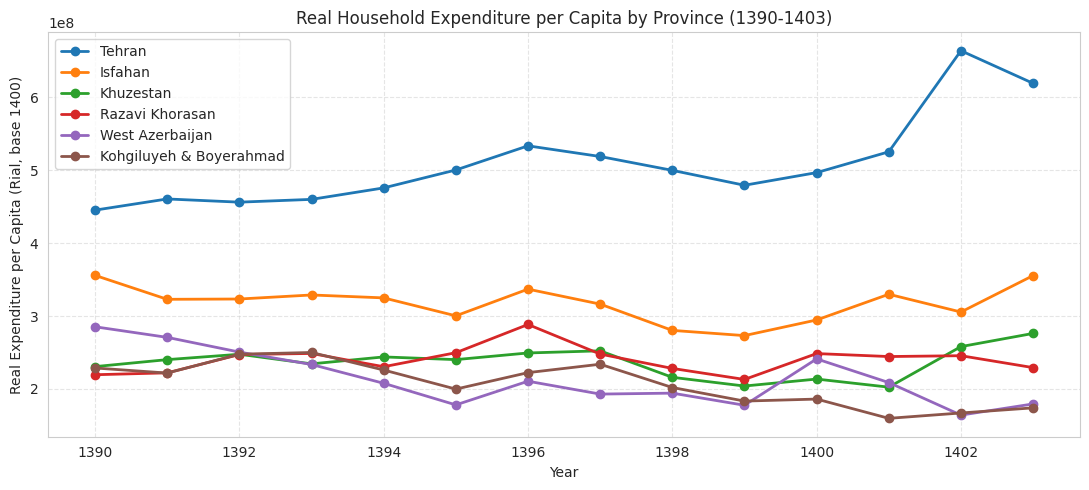

In [61]:
provinces_to_check = ['Tehran', 'Isfahan', 'Khuzestan', 'Razavi Khorasan', 'West Azerbaijan', 'Kohgiluyeh & Boyerahmad']

plt.figure(figsize=(11, 5))

for province in provinces_to_check:
    data = df_master[df_master['Province_EN'] == province].sort_values('Year')
    plt.plot(data['Year'], data['real_exp_per_capita'], marker='o', linewidth=2, label=province)

plt.title('Real Household Expenditure per Capita by Province (1390-1403)')
plt.xlabel('Year')
plt.ylabel('Real Expenditure per Capita (Rial, base 1400)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

The relation between NTL per capita and Exp in tehran

In [62]:
# Check Tehran NTL per capita vs expenditure over time
tehran = df_master[df_master['Province_EN'] == 'Tehran'].sort_values('Year')
print(tehran[['Year', 'NTL_Per_Capita', 'real_exp_per_capita']].to_string())

     Year  NTL_Per_Capita  real_exp_per_capita
27   1390             NaN         4.452095e+08
58   1391        0.005668         4.605376e+08
89   1392        0.006279         4.561449e+08
120  1393        0.006481         4.599648e+08
151  1394        0.006405         4.756849e+08
182  1395        0.006716         5.002501e+08
213  1396        0.007109         5.333677e+08
244  1397        0.007056         5.187494e+08
275  1398        0.007118         4.997518e+08
306  1399        0.007202         4.793168e+08
337  1400        0.007087         4.966608e+08
368  1401        0.007461         5.251845e+08
399  1402        0.008141         6.637919e+08
430  1403        0.008556         6.190627e+08


Between relation for each province

In [63]:
# Cross-sectional correlation by year — removes panel inflation effect
for year, group in df_master.dropna(subset=['NTL_Per_Capita', 'real_exp_per_capita']).groupby('Year'):
    r, _ = pearsonr(np.log(group['NTL_Per_Capita']), np.log(group['real_exp_per_capita']))
    print(f"Year {year}: r = {r:.3f}")

Year 1391: r = -0.401
Year 1392: r = -0.155
Year 1393: r = -0.178
Year 1394: r = -0.270
Year 1395: r = -0.102
Year 1396: r = -0.294
Year 1397: r = -0.279
Year 1398: r = -0.421
Year 1399: r = -0.315
Year 1400: r = -0.404
Year 1401: r = -0.401
Year 1402: r = -0.362
Year 1403: r = -0.307


in this part I validate NTL with Expenditure but not any NTL it is Annual NTL which differnce with Sum NTL is Annual NTL is the mean of NTL of each pixel of a province and sum is simply the total light for a province no matter the number of the pixels

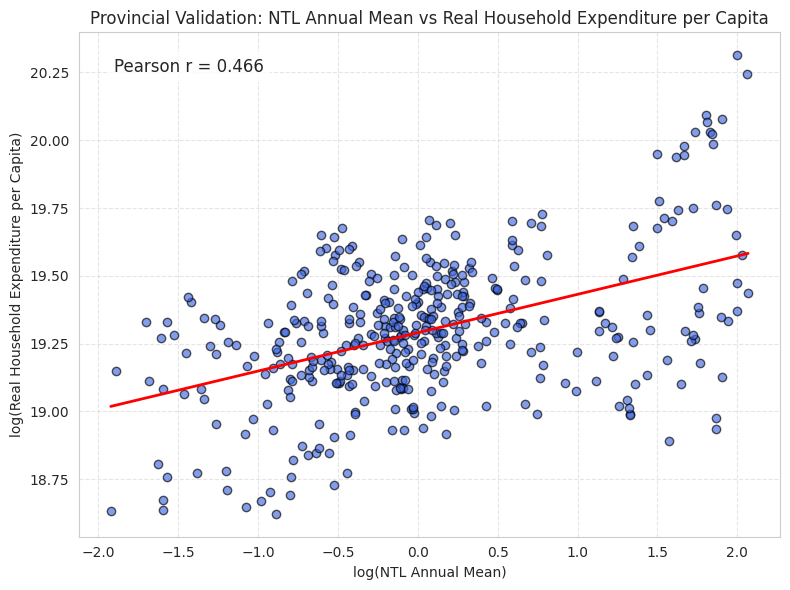

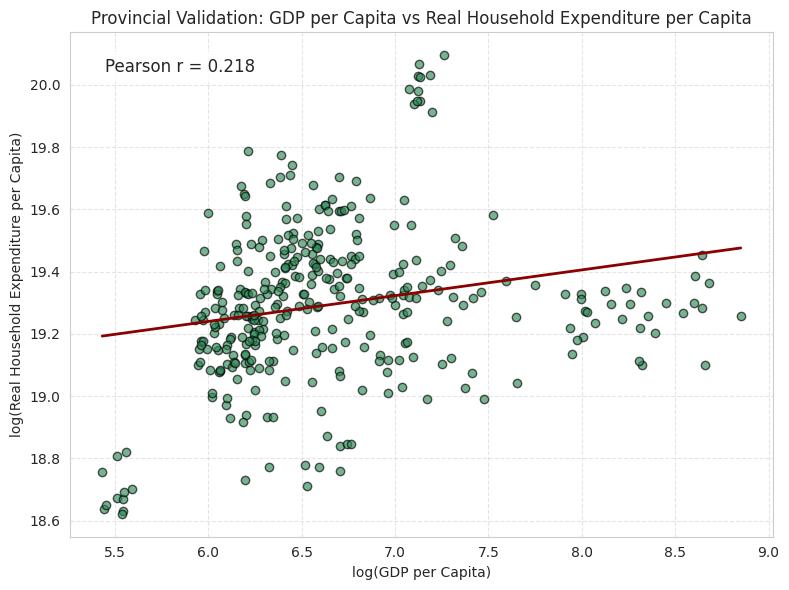

In [64]:
# ============================================================
# Scatter 1: NTL Annual Mean vs Real Household Expenditure per Capita
# ============================================================

df_plot1 = df_master[['log_Annual_Mean', 'log_real_exp_per_capita']].dropna()

r1, _ = pearsonr(df_plot1['log_Annual_Mean'], df_plot1['log_real_exp_per_capita'])
beta1, intercept1 = np.polyfit(df_plot1['log_Annual_Mean'], df_plot1['log_real_exp_per_capita'], 1)

plt.figure(figsize=(8, 6))
plt.scatter(df_plot1['log_Annual_Mean'], df_plot1['log_real_exp_per_capita'],
            alpha=0.65, edgecolors='k', color='royalblue')

x1 = np.linspace(df_plot1['log_Annual_Mean'].min(), df_plot1['log_Annual_Mean'].max(), 100)
plt.plot(x1, intercept1 + beta1 * x1, color='red', linewidth=2)

plt.text(0.05, 0.95, f'Pearson r = {r1:.3f}',
         transform=plt.gca().transAxes, fontsize=12,
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8))

plt.title('Provincial Validation: NTL Annual Mean vs Real Household Expenditure per Capita')
plt.xlabel('log(NTL Annual Mean)')
plt.ylabel('log(Real Household Expenditure per Capita)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# ============================================================
# Scatter 2: GDP per Capita vs Real Household Expenditure per Capita
# ============================================================

df_plot2 = df_master[['log_GDP_per_Capita', 'log_real_exp_per_capita']].dropna()

r2, _ = pearsonr(df_plot2['log_GDP_per_Capita'], df_plot2['log_real_exp_per_capita'])
beta2, intercept2 = np.polyfit(df_plot2['log_GDP_per_Capita'], df_plot2['log_real_exp_per_capita'], 1)

plt.figure(figsize=(8, 6))
plt.scatter(df_plot2['log_GDP_per_Capita'], df_plot2['log_real_exp_per_capita'],
            alpha=0.65, edgecolors='k', color='seagreen')

x2 = np.linspace(df_plot2['log_GDP_per_Capita'].min(), df_plot2['log_GDP_per_Capita'].max(), 100)
plt.plot(x2, intercept2 + beta2 * x2, color='darkred', linewidth=2)

plt.text(0.05, 0.95, f'Pearson r = {r2:.3f}',
         transform=plt.gca().transAxes, fontsize=12,
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8))

plt.title('Provincial Validation: GDP per Capita vs Real Household Expenditure per Capita')
plt.xlabel('log(GDP per Capita)')
plt.ylabel('log(Real Household Expenditure per Capita)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Spearman for NTL and GDP

before I estimate spearman correlation by using rank of each province in its category. I regress province i rank in NTL in year t on the GDP rank of province i in year t. so it give a coefficent for each year and I report the trend of the coeeficent. in this part i do same but instead of rank i use the normal of each 

In [65]:
def min_max_normalize(series):
    """Min-max scale a series to [0, 1]. Returns as-is if all values are NaN."""
    if series.notna().sum() == 0:
        return series
    return (series - series.min()) / (series.max() - series.min())

In [66]:
df_master['GDP_score'] = (
    df_master.groupby('Year')['GDP_per_Capita']
    .transform(min_max_normalize)
)

In [67]:
df_master['NTL_score'] = (
    df_master.groupby('Year')['NTL_Per_Capita']
    .transform(min_max_normalize)
)

In [68]:
benchmark_year = 1400

check = df_master[df_master['Year'] == benchmark_year][
    ['Province_EN', 'GDP_per_Capita', 'GDP_score', 'NTL_Per_Capita', 'NTL_score']
].sort_values('GDP_score', ascending=False)

print(check.to_string())

                   Province_EN  GDP_per_Capita  GDP_score  NTL_Per_Capita  NTL_score
312                    Bushehr     5474.674410   1.000000        0.120884   0.778683
324                  Khuzestan     2900.187158   0.506557        0.088387   0.556312
325    Kohgiluyeh & Boyerahmad     2102.109882   0.353592        0.090325   0.569577
320                       Ilam     1765.973483   0.289166        0.153228   1.000000
339                       Yazd     1734.754513   0.283182        0.066554   0.406916
337                     Tehran     1254.736318   0.191179        0.007087   0.000000
334                     Semnan     1208.424210   0.182302        0.079816   0.497662
328                    Markazi     1196.941961   0.180102        0.028601   0.147217
319                  Hormozgan     1122.989857   0.165927        0.036711   0.202709
340                     Zanjan      905.339970   0.124211        0.021919   0.101489
321                    Isfahan      894.594656   0.122152        

In [69]:
import os
out_dir = str(ROOT / "data/Validation")

df_master.to_excel(os.path.join(out_dir, "hies_ntl_gdp_master.xlsx"), index=False)
df_master.to_stata(os.path.join(out_dir, "hies_ntl_gdp_master.dta"), write_index=False, version=118)

print("Saved.")
print(df_master[['GDP_score', 'NTL_score']].describe())

Saved.
        GDP_score   NTL_score
count  341.000000  403.000000
mean     0.155155    0.199894
std      0.209078    0.251177
min      0.000000    0.000000
25%      0.049030    0.056520
50%      0.083301    0.087894
75%      0.162963    0.197738
max      1.000000    1.000000


In [70]:
results_by_year = []

for year, group in df_master.dropna(subset=['GDP_score', 'NTL_score']).groupby('Year'):
    X = sm.add_constant(group['GDP_score'])
    y = group['NTL_score']
    model = sm.OLS(y, X).fit()
    
    results_by_year.append({
        'Year': year,
        'N': int(model.nobs),
        'beta': model.params['GDP_score'],
        'se_beta': model.bse['GDP_score'],
        'p_value': model.pvalues['GDP_score'],
        'r_squared': model.rsquared
    })

results_df = pd.DataFrame(results_by_year)
print(results_df.to_string(index=False))

 Year  N     beta  se_beta      p_value  r_squared
 1391 31 0.804197 0.102527 1.191701e-08   0.679643
 1392 31 0.950791 0.146773 4.330557e-07   0.591344
 1393 31 0.946713 0.137395 1.431415e-07   0.620809
 1394 31 0.877251 0.098490 8.516569e-10   0.732313
 1395 31 1.073731 0.125711 2.075983e-09   0.715556
 1396 31 0.764269 0.123930 1.008588e-06   0.567364
 1397 31 0.924730 0.131028 9.189808e-08   0.632017
 1398 31 1.055210 0.156300 2.076170e-07   0.611149
 1399 31 1.025146 0.154570 2.856736e-07   0.602668
 1400 31 0.923835 0.156630 2.106796e-06   0.545373


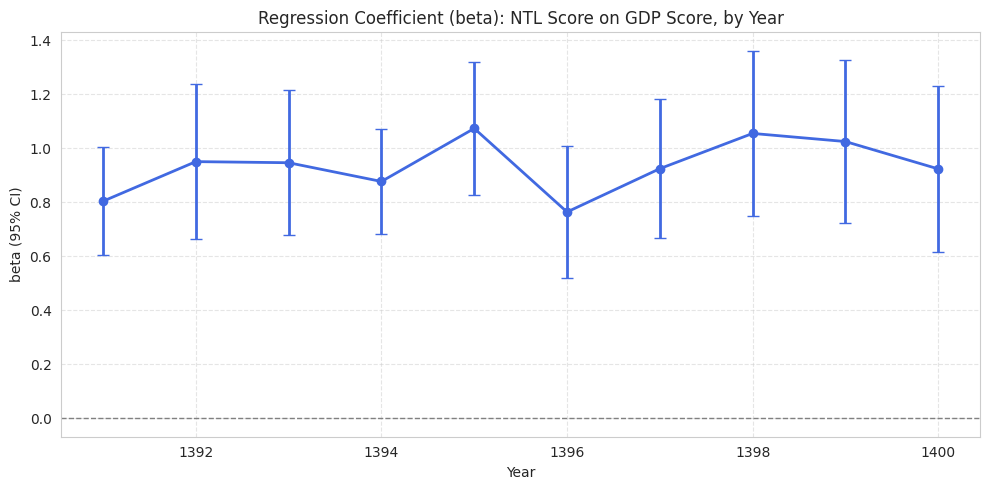

In [71]:
plt.figure(figsize=(10, 5))

plt.errorbar(
    results_df['Year'],
    results_df['beta'],
    yerr=1.96 * results_df['se_beta'],
    marker='o',
    linewidth=2,
    capsize=4,
    color='royalblue'
)

plt.axhline(0, linestyle='--', color='gray', linewidth=1)

plt.title('Regression Coefficient (beta): NTL Score on GDP Score, by Year')
plt.xlabel('Year')
plt.ylabel('beta (95% CI)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

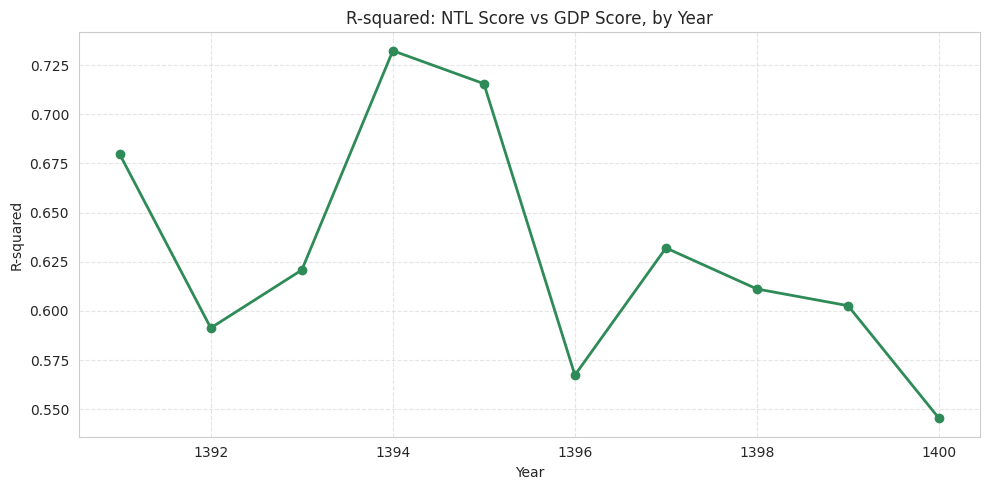

In [72]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df['Year'],
    results_df['r_squared'],
    marker='o',
    linewidth=2,
    color='seagreen'
)

plt.title('R-squared: NTL Score vs GDP Score, by Year')
plt.xlabel('Year')
plt.ylabel('R-squared')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Residual of the regressions

in this part I regress NTL, Expenditure and GDP per capita and save the residuals in the df_master

In [75]:
# Regression 1: NTL on population + province FE + year FE
model_ntl = smf.ols(
    'log_NTL_Per_Capita ~ np.log(Population) + C(Province_EN) + C(Year)',
    data=df_master
).fit()
df_master['resid_ntl'] = model_ntl.resid

# Regression 2: Expenditure on population + province FE + year FE
model_exp = smf.ols(
    'log_real_exp_per_capita ~ np.log(Population) + C(Province_EN) + C(Year)',
    data=df_master
).fit()
df_master['resid_exp'] = model_exp.resid

model_gdp = smf.ols(
    'log_GDP ~ np.log(Population) + C(Province_EN) + C(Year)',
    data=df_master
).fit()
df_master['resid_gdp'] = model_gdp.resid

In [77]:
from scipy.stats import pearsonr
r, p = pearsonr(df_master['resid_ntl'].dropna(), df_master['resid_exp'].dropna())
print(f"Correlation of residuals (NTL vs Expenditure, controlling for population + FE): {r:.3f}")

Correlation of residuals (NTL vs Expenditure, controlling for population + FE): -0.146
